## Parcels fieldset.from_NEMO using Glorysv12 w fixed, with adaptive sub-stepping at solid boundaries
v3: release polygon from `Analysis/v4.release_polygon_glorys.ipynb` (no land carving). Particles that fall on land
(T mask) are counted and deleted right after the release, to find how many particles are needed for 10K wet ones. 1-day run.

In [ ]:
num_particles = 16_400
run_time_days = 20
time_step_minutes = 20
out_put_step_hours = 6

depth_min = 0 #todo: figure near-surface depths 
depth_max = 7

offset = 300

n_wet_target = 10000   # particles wanted inside wet cells
ref_date = "1993-01-01"
#reproducibility
rdm_seed = 11098723

#paths
pathUVW= '/work/bk1450/b383184/Amazon/Mercator/data/variables_c/UVW'
pathTS = "/work/bk1450/b383184/Amazon/Mercator/data/variables_c/tracers"
Hgr = "/work/bk1450/b383184/Amazon/Mercator/data/Hgr_cmesh.nc"
Zgr = "/work/bk1450/b383184/Amazon/Mercator/data/Zgr_cmesh2.nc"

In [51]:
import numpy as np

In [52]:
# --- release polygon (from Analysis/v4.release_polygon_glorys.ipynb) ---
# red square (-51.2..-48 E, -1.5..1.5 N) with the corners/pieces cut by the green lines
# vertices go clockwise, each one is a line end on the square edge (or where two lines meet)
from shapely.geometry import Polygon

release_poly = Polygon([
    (-51.2,  0.1 ),   # west edge  (start of NW cut line)
    (-50.0,  1.5 ),   # north edge (end of NW cut line)
    (-49.9,  1.5 ),   # north edge (start of NE cut line)
    (-48.0, -0.65),   # east edge  (end of NE cut line)
    (-48.0, -0.8 ),   # east edge  (start of SE cut line)
    (-48.4, -1.5 ),   # south edge (end of SE cut line)
    (-48.9, -1.5 ),   # south edge (start of Para line)
    (-48.6, -0.5 ),   # where the Para line meets the Marajo line
    (-51.2, -0.2 ),   # west edge  (end of Marajo line)
])
print("valid:", release_poly.is_valid, "  area (deg2):", release_poly.area)

poly_lons, poly_lats = np.array(release_poly.exterior.coords).T


valid: True   area (deg2): 3.7375000000000043


In [53]:
out_path = f'tracks_v3_{rdm_seed}/' #path to store the particle zarr

start_time = np.datetime64(ref_date) + np.timedelta64(offset, "D")
start_time

np.datetime64('1993-10-28')

In [54]:
import pandas as pd
start_time = pd.to_datetime(start_time)
t_plus_2y = start_time + pd.DateOffset(years=2)

st_yr = str(start_time)[0:4]
end_yr = str(t_plus_2y)[0:4]

print(st_yr)
print(end_yr)

1993
1995


## Particles from the ARP to the Atlantic

In [55]:
from parcels import ParticleSet
from parcels import JITParticle
# from parcels import ScipyParticle
from parcels import AdvectionRK4_3D
from parcels import AdvectionRK4
from parcels import Variable
from datetime import timedelta
import numpy as np
from parcels import FieldSet
from glob import glob

In [56]:
np.random.seed(rdm_seed)

In [57]:
from pathlib import Path
import os

def files_span(base, prefix, st_yr, end_yr, suffix='c.nc'):
    # all months from the month BEFORE the release to Dec end_yr.
    # Records sit at 12:00 each day, so a release on the 1st at 00:00 (e.g. offset 365, 730)
    # falls before the first record of its own month -> the previous month's file is needed.
    first_month = start_time.to_period('M') - 1
    months = pd.period_range(first_month, f'{end_yr}-12', freq='M')
    pats = [Path(base) / f"{prefix}_{p.year}-{p.month:02d}{suffix}" for p in months]
    # keep only existing files
    return [str(p) for p in pats if p.exists()]

ufiles = files_span(pathUVW, 'U', st_yr, end_yr, 'c.nc')
vfiles = files_span(pathUVW, 'V', st_yr, end_yr, 'c.nc')
wfiles = files_span(pathUVW, 'W', st_yr, end_yr, 'fc.nc') 
tfiles = files_span(pathTS,  'T', st_yr, end_yr, 'c.nc')
sfiles = files_span(pathTS,  'S', st_yr, end_yr, 'c.nc')

In [58]:
## define the fieldset
filenames = {
    "U": {
        "data":ufiles,
        "lon": Hgr,
        "lat": Hgr,
        "depth": wfiles[0],
    },
    
    "V": {
        "data": vfiles,
        "lon": Hgr,
        "lat": Hgr,
        "depth": wfiles[0],
    },
    
    "W": {
        "data": wfiles,
        "lon": Hgr,
        "lat": Hgr,
        "depth": wfiles[0],
    },

    "T": {
        "data": tfiles,
        "lon": Hgr,
        "lat": Hgr,
        "depth": wfiles[0], #Changed to Wfiles instead of tfiles
    },#on the t points

    "S": {
        "data": sfiles,
        "lon": Hgr,
        "lat": Hgr,
        "depth": wfiles[0], #Changed to Wfiles instead of tfiles
    }
}


variables = {
    "U": "vozocrtx",
    "V": "vomecrty",
    "W": "vovecrtz",
    "T": "votemper",
    "S": "vosaline",
}

interp_method = {
    "U":"cgrid_velocity",
    "V":"cgrid_velocity",
    "W":"cgrid_velocity",
    "T":"cgrid_velocity",
    "S":"cgrid_velocity",
}


dimensions = {
    "U": {"lon": "glamf", "lat": "gphif", "depth": "depthw", "time": "time_counter"},
    "V": {"lon": "glamf", "lat": "gphif", "depth": "depthw", "time": "time_counter"},
    "W": {"lon": "glamf", "lat": "gphif", "depth": "depthw", "time": "time_counter"},
    "T": {"lon": "glamf", "lat": "gphif", "depth": "depthw", "time": "time_counter"},
    "S": {"lon": "glamf", "lat": "gphif", "depth": "depthw", "time": "time_counter"},
}


## now the fieldset
fieldset = FieldSet.from_nemo(
    filenames, 
    variables, 
    dimensions,
    # interp_method = interp_method,
    # tracer_interp_method="cgrid_tracer",
    deferred_load=True,
    allow_time_extrapolation = False,
    # gridindexingtype = "nemo",
)


In [59]:
# --- T mask (as in Analysis/v4.release_polygon_glorys.ipynb) ---
# k_last = index of the deepest wet T level of each column (NaN = land). T = cell centre, so this is the
# mask of the tracer cells; the release polygon is NOT carved, land seeds are counted and deleted below.
import xarray as xr

_t = xr.open_dataset(tfiles[0]).votemper.isel(time_counter=0)
nwater = _t.notnull().sum('deptht')
T_mask = (nwater - 1).where(nwater > 0).values      # (y, x): k_last, NaN on land

_h = xr.open_dataset(Hgr)
glamf = _h.glamf.isel(t=0).values          # f points = cell corners
gphif = _h.gphif.isel(t=0).values
depthw = xr.open_dataset(wfiles[0]).depthw.values


In [60]:
# uniform seeding inside the release polygon (land included) (rejection sampling in its bounding box)
from shapely.geometry import Point
from shapely.prepared import prep

_wb = prep(release_poly)
wl, ws, wr, wn = release_poly.bounds

start_lon = np.empty(num_particles)
start_lat = np.empty(num_particles)
n = 0
while n < num_particles:
    batch = max(num_particles - n, 1) * 3          # over-sample, most fall outside
    x = np.random.uniform(wl, wr, size=batch)
    y = np.random.uniform(ws, wn, size=batch)
    keep = np.fromiter((_wb.contains(Point(a, b)) for a, b in zip(x, y)),
                       dtype=bool, count=batch)
    x, y = x[keep], y[keep]
    take = min(len(x), num_particles - n)
    start_lon[n:n+take] = x[:take]
    start_lat[n:n+take] = y[:take]
    n += take

start_depth = np.random.uniform(depth_min, depth_max, size=num_particles)
start_times = np.datetime64(start_time)


In [61]:
def SampleTS(particle, fieldset, time):
    # z = particle.depth
    # Optional: clamp depth to tracer range if needed
    # zmin, zmax can be added as constants if you want; otherwise omit.
    particle.temp = fieldset.T[time, particle.depth, particle.lat, particle.lon]
    particle.sal  = fieldset.S[time, particle.depth, particle.lat, particle.lon]

In [62]:
class SampleParticle(JITParticle):
    """
    Add variables to the standard particle class.
    Sampling temperature, salinity and age of the particle.
    """

    temp = Variable("temp", dtype=np.float32,initial=np.nan)
    sal = Variable("sal", dtype=np.float32,initial=np.nan)
    nrefine = Variable("nrefine", dtype=np.int32, initial=0)   # sub-steps redone with half the step (cumulative)
    ndry = Variable("ndry", dtype=np.int32, initial=0)         # sub-steps taken although in a zero-velocity cell (should stay 0)
    # age = Variable("age", dtype=np.float32,initial=0.0)

In [63]:
pset = ParticleSet(
    fieldset=fieldset,
    pclass = SampleParticle,
    lon = start_lon,
    lat = start_lat,
    depth=start_depth,
    time=start_times
) 

out_fn = f'Parcels_run_{rdm_seed}_{start_time}.zarr'

output_file = pset.ParticleFile(
    name=out_path+out_fn,
    outputdt=timedelta(hours=out_put_step_hours),
    chunks = (num_particles,int(run_time_days*24/out_put_step_hours/4))
)

## Particles deleted in land (T mask)


In [64]:
# --- particles released on land (T mask) -> delete them ---
# NEMO/parcels convention: T cell (j,i) has corners f(j-1,i-1)..f(j,i). Find the cell of each seed with
# point-in-quad tests, then it is land if the T column is dry, or if the seed is below the column bottom
# depthw[k_last+1] (parcels uses the 1-D depthw levels).
from shapely import STRtree, points

bl, bs, br, bn = release_poly.bounds
_in = (glamf >= bl-0.2) & (glamf <= br+0.2) & (gphif >= bs-0.2) & (gphif <= bn+0.2)
_j, _i = np.where(_in)
cells, cell_ji = [], []
for j in range(_j.min()+1, _j.max()+1):
    for i in range(_i.min()+1, _i.max()+1):
        cells.append(Polygon([(glamf[j-1, i-1], gphif[j-1, i-1]), (glamf[j-1, i], gphif[j-1, i]),
                              (glamf[j,   i  ], gphif[j,   i  ]), (glamf[j,   i-1], gphif[j,   i-1])]))
        cell_ji.append((j, i))
cell_ji = np.array(cell_ji)

p_idx, c_idx = STRtree(cells).query(points(start_lon, start_lat), predicate='intersects')
cell_of = np.full(num_particles, -1)
cell_of[p_idx] = c_idx                      # a seed on a cell edge keeps one of its cells
assert (cell_of >= 0).all(), "some seeds are outside the cell window"

jj, ii = cell_ji[cell_of].T
k_last = T_mask[jj, ii]
on_land = np.isnan(k_last)
below_bed = ~on_land & (start_depth > depthw[np.nan_to_num(k_last, nan=0).astype(int) + 1])
dry = on_land | below_bed

# cross-check with parcels: land velocities are zeroed on load, so UVW == 0 means a dry cell
fieldset.computeTimeChunk(fieldset.U.grid.time[0], 1)
_t0 = fieldset.U.grid.time[0]
uvw_zero = np.array([fieldset.UVW[_t0, d, la, lo] == (0.0, 0.0, 0.0)
                     for lo, la, d in zip(start_lon, start_lat, start_depth)])

n_dry = int(dry.sum())
n_wet = num_particles - n_dry
wet_frac = n_wet / num_particles
print(f"released            : {num_particles}")
print(f"on land (T mask)    : {int(on_land.sum())}")
print(f"below sea bed       : {int(below_bed.sum())}")
print(f"deleted in land     : {n_dry}  ({100*n_dry/num_particles:.2f}%)")
print(f"left in wet cells   : {n_wet}  ({100*wet_frac:.2f}%)")
print(f"parcels UVW == 0    : {int(uvw_zero.sum())}  (T-mask dry & UVW == 0: {int((dry & uvw_zero).sum())})")
print(f"-> to get {n_wet_target} wet particles release ~{int(np.ceil(n_wet_target / wet_frac))}")

pset.remove_indices(np.where(dry)[0])
print("particles in pset after deletion:", pset.size)


released            : 16400
on land (T mask)    : 6389
below sea bed       : 0
deleted in land     : 6389  (38.96%)
left in wet cells   : 10011  (61.04%)
parcels UVW == 0    : 6389  (T-mask dry & UVW == 0: 6389)
-> to get 10000 wet particles release ~16382
particles in pset after deletion: 10011


Text(0.5, 1.0, 'Release: 10011 wet / 6389 on land (grey = T-mask land)')

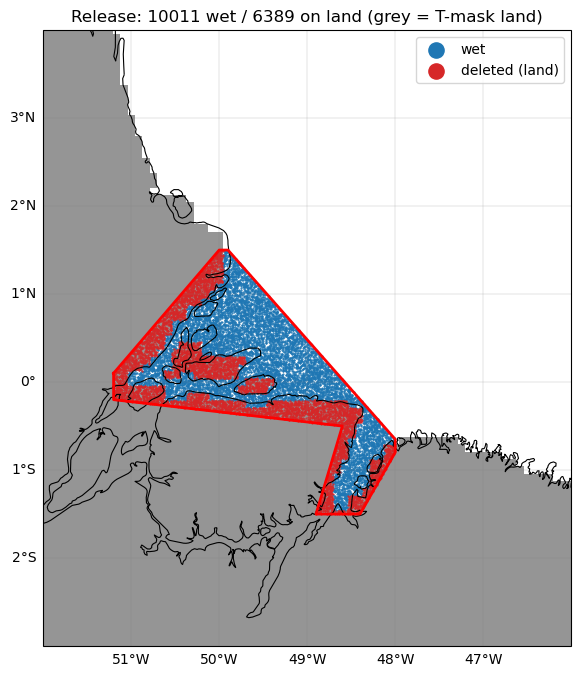

In [65]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

fig, ax = plt.subplots(figsize=(10, 8), subplot_kw=dict(projection=ccrs.PlateCarree()))
ax.set_extent([-52, -46, -3, 4], crs=ccrs.PlateCarree())
ax.pcolormesh(glamf, gphif, np.isnan(T_mask)[1:, 1:],
              cmap='Greys', vmin=0, vmax=2, transform=ccrs.PlateCarree(), shading='flat')
ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)
ax.plot(poly_lons, poly_lats, color='r', lw=2, transform=ccrs.PlateCarree(), zorder=4)
ax.scatter(start_lon[~dry], start_lat[~dry], s=0.3, c='tab:blue', transform=ccrs.PlateCarree(), label='wet')
ax.scatter(start_lon[dry], start_lat[dry], s=0.3, c='tab:red', transform=ccrs.PlateCarree(), label='deleted (land)')
gl = ax.gridlines(draw_labels=True, linewidth=0.3, color='gray', alpha=0.5)
gl.top_labels = False
gl.right_labels = False
ax.legend(markerscale=20, loc="upper right")
plt.title(f'Release: {n_wet} wet / {n_dry} on land (grey = T-mask land)')


In [66]:
##check the error
def CheckError(particle, fieldset, time):
    if particle.state >= 50:  # This captures all Errors
        particle.delete()

# The domain ends at 30.07N (Florida Current exit). A particle that reaches the edge makes every
# UVW lookup fail with a 1e6-iteration cell search, and AdvectionRK4_3D_substep keeps halving h on
# the failed (zero) velocities -> thousands of failed searches per particle (runs hit the 4 h limit).
# Remove particles before they get there.
fieldset.add_constant("lat_max", 29.8)

def DeleteNorth(particle, fieldset, time):
    if particle.lat > fieldset.lat_max:
        particle.delete()

In [67]:
import math

# RK4-3D with sub-stepping at solid boundaries, done inside the kernel (no StatusCode.Repeat, particle.dt stays constant).
# A trial step whose RK4 stages or end point fall in a cell with u = v = w = 0 (ground) is not taken:
# the sub-step h is halved and recomputed (down to fieldset.dt_min); after an accepted sub-step h doubles back.
def AdvectionRK4_3D_substep(particle, fieldset, time):
    lon0 = particle.lon
    lat0 = particle.lat
    dep0 = particle.depth
    t = time
    remaining = particle.dt
    h = particle.dt
    while remaining > 1e-6:
        if h > remaining:
            h = remaining
        (u1, v1, w1) = fieldset.UVW[t, dep0, lat0, lon0, particle]
        lon1 = lon0 + u1 * 0.5 * h
        lat1 = lat0 + v1 * 0.5 * h
        dep1 = dep0 + w1 * 0.5 * h
        (u2, v2, w2) = fieldset.UVW[t + 0.5 * h, dep1, lat1, lon1, particle]
        lon2 = lon0 + u2 * 0.5 * h
        lat2 = lat0 + v2 * 0.5 * h
        dep2 = dep0 + w2 * 0.5 * h
        (u3, v3, w3) = fieldset.UVW[t + 0.5 * h, dep2, lat2, lon2, particle]
        lon3 = lon0 + u3 * h
        lat3 = lat0 + v3 * h
        dep3 = dep0 + w3 * h
        (u4, v4, w4) = fieldset.UVW[t + h, dep3, lat3, lon3, particle]
        dlon = (u1 + 2 * u2 + 2 * u3 + u4) / 6 * h
        dlat = (v1 + 2 * v2 + 2 * v3 + v4) / 6 * h
        ddep = (w1 + 2 * w2 + 2 * w3 + w4) / 6 * h
        (u5, v5, w5) = fieldset.UVW[t + h, dep0 + ddep, lat0 + dlat, lon0 + dlon, particle]
        dry = 0
        if u2 == 0 and v2 == 0 and w2 == 0:
            dry = 1
        if u3 == 0 and v3 == 0 and w3 == 0:
            dry = 1
        if u4 == 0 and v4 == 0 and w4 == 0:
            dry = 1
        if u5 == 0 and v5 == 0 and w5 == 0:
            dry = 1
        if u1 == 0 and v1 == 0 and w1 == 0:
            dry = 2   # already in a zero-velocity cell: a smaller step cannot help
        if dry == 1 and h > fieldset.dt_min:
            h = h / 2
            particle.nrefine += 1
        else:
            lon0 = lon0 + dlon
            lat0 = lat0 + dlat
            dep0 = dep0 + ddep
            t = t + h
            remaining = remaining - h
            if dry > 0:
                particle.ndry += 1
            h = h * 2
    particle_dlon += lon0 - particle.lon  # noqa
    particle_dlat += lat0 - particle.lat  # noqa
    particle_ddepth += dep0 - particle.depth  # noqa


fieldset.add_constant("dt_min", 1.0)   # smallest sub-step [s]

In [68]:
## Execute particles
pset.execute(
    [DeleteNorth,SampleTS,AdvectionRK4_3D_substep,CheckError],
    runtime=timedelta(days=run_time_days),
    dt=timedelta(minutes=time_step_minutes),
    output_file= output_file
)

INFO: Output files are stored in tracks_v3_24/Parcels_run_24_1993-10-28 00:00:00.zarr.
100%|██████████| 1728000.0/1728000.0 [06:23<00:00, 4508.34it/s]


## Plotting

In [69]:
import xarray as xr

In [70]:
out_path = f'tracks_v3_{rdm_seed}/'
# out_fn = 'Parcels_run_692' 

ds_traj = xr.open_zarr(out_path+out_fn)
# ds_traj = ds_traj.compute()
ds_traj = ds_traj.compute()
ds_traj

<xarray.Dataset> Size: 45MB
Dimensions:     (trajectory: 10011, obs: 80)
Coordinates:
  * obs         (obs) int32 320B 0 1 2 3 4 5 6 7 8 ... 72 73 74 75 76 77 78 79
  * trajectory  (trajectory) int64 80kB 26400 26401 26403 ... 42796 42798 42799
Data variables:
    lat         (trajectory, obs) float64 6MB -0.8103 -0.8046 ... 0.8677 0.8729
    lon         (trajectory, obs) float64 6MB -48.13 -48.13 ... -50.21 -50.2
    ndry        (trajectory, obs) float64 6MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    nrefine     (trajectory, obs) float64 6MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    sal         (trajectory, obs) float32 3MB 24.06 24.05 24.04 ... 4.894 4.868
    temp        (trajectory, obs) float32 3MB 29.22 29.23 29.23 ... 29.47 29.22
    time        (trajectory, obs) datetime64[ns] 6MB 1993-10-28 ... 1993-11-1...
    z           (trajectory, obs) float64 6MB 3.588 3.5 3.421 ... 1.427 1.405
Attributes:
    Conventions:            CF-1.6/CF-1.7
    feature_type:           trajectory
    ncei_template_version:  NCEI_NetCDF_Trajectory_Template_v2.0
    parcels_kernels:        SampleParticleDeleteNorthSampleTSAdvectionRK4_3D_...
    parcels_mesh:           spherical
    parcels_version:        3.1.2

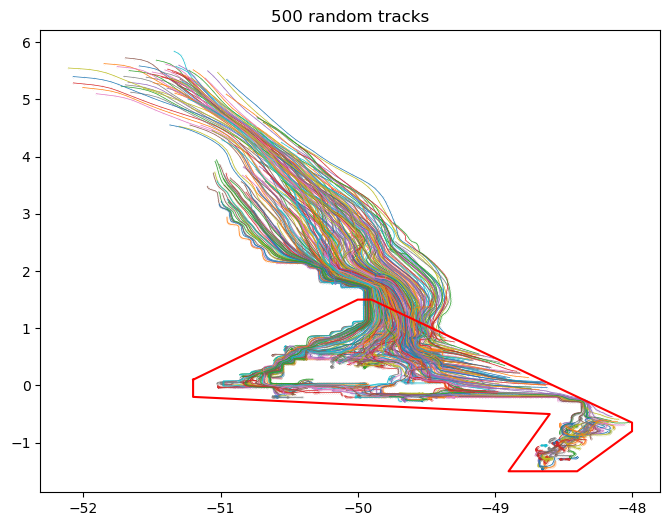

In [83]:
# import matplotlib.pyplot as plt
# for ii in range(min(ds_traj.sizes['trajectory'], 500)):
#     plt.plot(ds_traj.isel(trajectory=ii).lon.data, ds_traj.isel(trajectory=ii).lat.data,marker='.',markersize=0.1)

import matplotlib.pyplot as plt

rng = np.random.default_rng(201)   # own generator, doesn't touch the seeding RNG; change 0 for another sample
n_plot = min(ds_traj.sizes['trajectory'], 500)
pick = rng.choice(ds_traj.sizes['trajectory'], size=n_plot, replace=False)

sub = ds_traj.isel(trajectory=pick)
plt.figure(figsize=(8, 6))
plt.plot(sub.lon.values.T, sub.lat.values.T, marker='.', markersize=0.1, lw=0.5)
plt.plot(poly_lons, poly_lats, color='r', lw=1.5)   # release polygon
plt.title(f'{n_plot} random tracks')
plt.show()



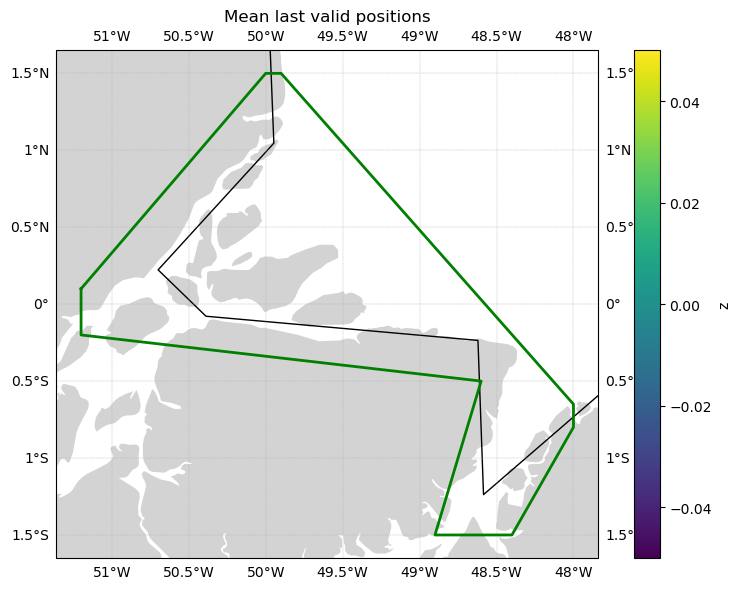

In [72]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

last_valid = ds_traj.lat.notnull().astype(int).diff('obs', label='lower') == -1
ends = ds_traj.where(last_valid).mean('obs').compute()

fig = plt.figure(figsize=(8, 6))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.coastlines(resolution='110m')
ax.add_feature(cfeature.LAND, facecolor='lightgray')
ax.gridlines(draw_labels=True, linestyle='--', linewidth=0.3)

ends.plot.scatter(
    x='lon',
    y='lat',
    hue='z' if 'z' in ends else None,
    cmap='viridis',
    s=30,
    ax=ax,
    transform=ccrs.PlateCarree()
)

ax.plot(poly_lons, poly_lats, color='green', lw=2)

plt.title('Mean last valid positions')
plt.tight_layout()
plt.show()

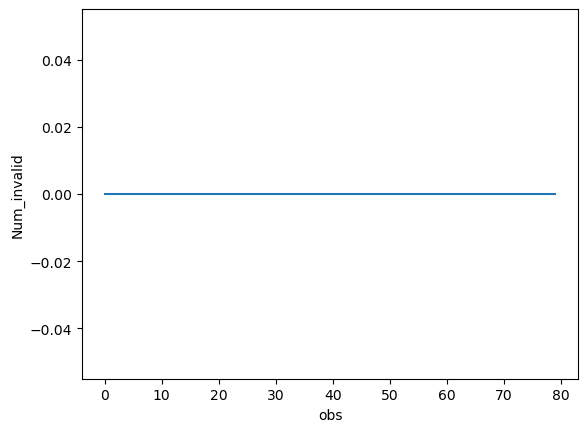

In [73]:
import matplotlib.pyplot as plt
ds_traj.lat.isnull().sum('trajectory').rename('Num_invalid').plot()
plt.show()